# Bassez et al. 2021 — Breast Cancer (10x)

**03 — Signatures.** Gate 2: is the embryonic module pattern present? Read module geography and the pseudotime gradient over the Body; the deliverable panels show **raw** per-cell scores.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation','pSom':'Somitogenesis','Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| Body cells with pseudotime:', int(adata.obs['t'].notna().sum()))
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]; print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 65837 | Body cells with pseudotime: 65837
Gast: 78/81 genes present
pSom: 93/98 genes present
Crest: 104/104 genes present


### Gate 2 — module geography
Smoothed spatial correlations across the manifold; pseudotime gradients over the Body; terminal-Crest and inverse pSom&Crest tests. A single (Gast/pSom)→Crest gradient with an inverse terminal Crest is the **non-branching GO** (§1); no bifurcation → Gate 3 = NA.

In [4]:
print('smoothed spatial correlations (whole manifold):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
body = adata[adata.obs['t'].notna()].copy()
t = body.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('gradient along pseudotime over the Body (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_=spearmanr(t, body.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = body.obs['Crest_sm'] >= body.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
pz=(body.obs['pSom']-body.obs['pSom'].mean())/body.obs['pSom'].std()
cz=(body.obs['Crest']-body.obs['Crest'].mean())/body.obs['Crest'].std()
joint=((pz>0.5)&(cz>0.5)).mean(); exp=(pz>0.5).mean()*(cz>0.5).mean()
print(f'joint pSom&Crest-high enrichment = {joint/exp:.2f} (<1 = inverse gradient, not a hub)')
gp = np.corrcoef(adata.obs['Gast_sm'],adata.obs['pSom_sm'])[0,1]
print('Gate 2: single (Gast/pSom)->Crest gradient + inverse terminal Crest -> GO (non-branching); '
      f'Gast/pSom co-vary (r={gp:+.2f}), no diverging arms')
print('Gate 3: no bifurcation -> NA')

smoothed spatial correlations (whole manifold):
  Gast_sm vs pSom_sm: r = -0.21
  Crest_sm vs Gast_sm: r = -0.24
  Crest_sm vs pSom_sm: r = -0.82
gradient along pseudotime over the Body (Spearman rho on smoothed):
  Gast_sm: rho = -0.113
  pSom_sm: rho = -0.316
  Crest_sm: rho = +0.323
Neural-crest-high decile mean pseudotime = 0.40 (terminal if ~1)
joint pSom&Crest-high enrichment = 0.23 (<1 = inverse gradient, not a hub)
Gate 2: single (Gast/pSom)->Crest gradient + inverse terminal Crest -> GO (non-branching); Gast/pSom co-vary (r=-0.21), no diverging arms
Gate 3: no bifurcation -> NA


### Figures — raw per-cell signatures (deliverables)
Raw `score_genes` values on the house layout; external colorbars saved to `colorbars/`.

<string>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<string>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<string>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


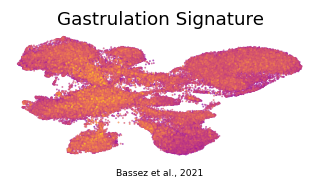

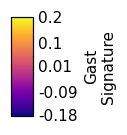

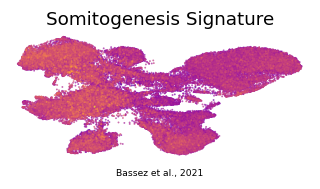

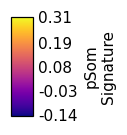

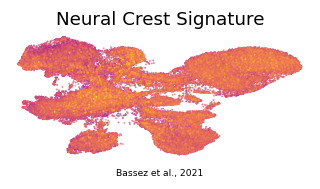

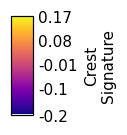

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles={'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=6, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo,hi_=float(adata.obs[m].min()),float(adata.obs[m].max())
    ticks=np.round(np.linspace(lo,hi_,5),2)
    fcb=plt.figure(figsize=(.66,1)); cax=fcb.add_axes([.35,.05,.3,.9])
    cb=plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (65837, 22208)
